In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from src.config import *
RES = RES_DIR
def show(name, width=900):
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=width))


# 03 · Feature engineering

**Question.** Do graph and time features add value beyond the 165 supplied columns, without using information from the future?

Engineered features (`src/feature_engineering.py`):
* `in_degree`, `out_degree`, `degree`: how many transactions feed into / receive from this one;
* `step_tx_count`: number of transactions in the same time step (a market-activity indicator);
* for the 8 most important local features (chosen by a Random Forest fitted on **training rows only**), the **mean over in-neighbours and out-neighbours**.

**No-leakage argument.** All edges join transactions of the same time step (checked in notebook 01), so every feature uses only same-step information. Neighbour *labels* are never used (that would leak the target).

neighbour columns: ['local_41', 'local_53', 'local_47', 'local_43', 'local_55', 'local_90', 'local_49', 'local_23']
engineered columns: 20


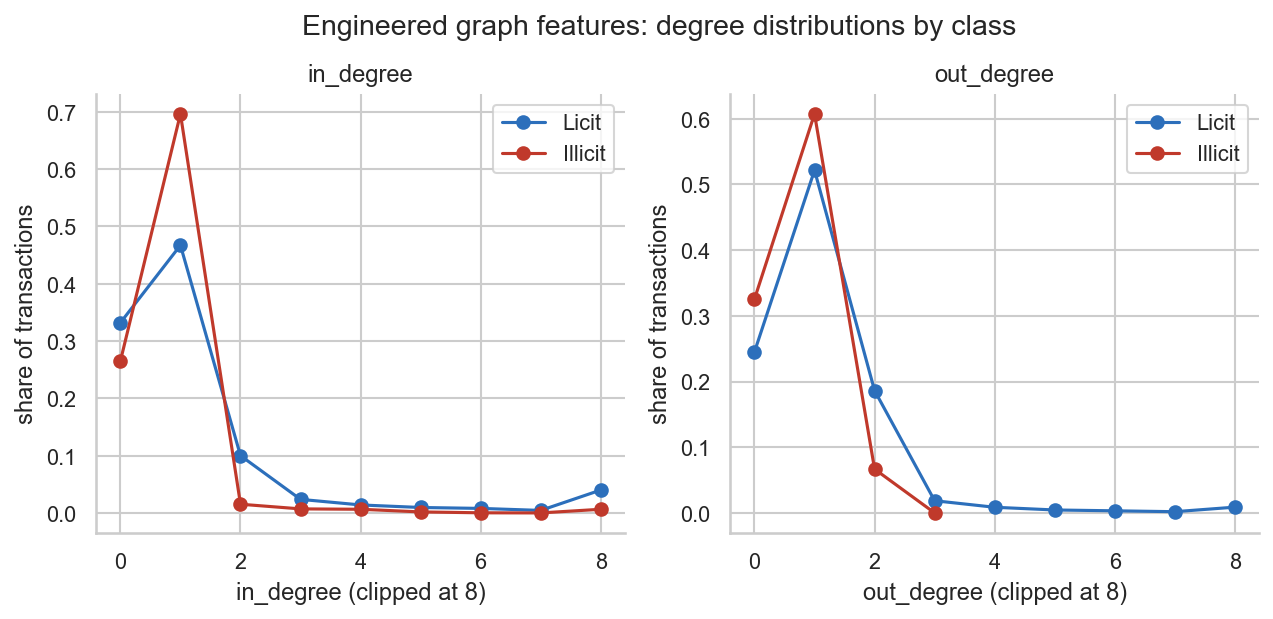

,in_degree,out_degree,degree
label,,,
0,1.91,1.19,3.10
1,1.27,0.74,2.01


In [2]:
from src import plots
from src.data_loader import load_master, labelled
from src.feature_engineering import add_graph_features
master, edges = load_master()
meta = json.loads((RES / "run_metadata.json").read_text())
eng = add_graph_features(master, edges, meta["neighbour_cols"])
df = pd.concat([master, eng], axis=1); df = df[df.label >= 0]
print("neighbour columns:", meta["neighbour_cols"]); print("engineered columns:", len(meta["engineered_cols"]))
plots.fig_degree(df); show("fe_01_degree", 850)
df.groupby("label")[["in_degree", "out_degree", "degree"]].mean().round(2)

**Insight.** Illicit transactions are less connected: mean total degree 2.0 vs 3.1 for licit. Only 6.7% of illicit transactions have an out-degree of 2 or more, versus 23.3% of licit ones. So degree carries some information, but the distributions overlap heavily (median 1 for both classes).

In [3]:
sel = pd.read_csv(RES / "feature_set_selection.csv"); print("Chosen by expanding-window CV on steps 1-34 (XGBoost, default settings):"); display(sel.round(4))
ab = pd.read_csv(RES / "feature_ablation.csv")
ab.pivot_table(index=["model", "feature_set"], columns="period", values=["f1", "pr_auc"]).round(3)

Chosen by expanding-window CV on steps 1-34 (XGBoost, default settings):


,feature_set,n_features,cv_pr_auc_mean,fold1,fold2,fold3
0,raw_165,165,0.9464,0.9865,0.8653,0.9874
1,raw_165+engineered,185,0.9455,0.9864,0.8608,0.9892


f1        pr_auc       
period                     test    val   test    val
model feature_set                                   
rf    aggregated_only_72  0.574  0.751  0.606  0.828
      local_only_93       0.779  0.957  0.773  0.989
      raw_165             0.757  0.965  0.784  0.989
      raw_165+engineered  0.796  0.967  0.786  0.989
xgb   aggregated_only_72  0.627  0.750  0.632  0.852
      local_only_93       0.721  0.937  0.750  0.983
      raw_165             0.776  0.950  0.783  0.985
      raw_165+engineered  0.762  0.960  0.781  0.990

**Insight (does feature engineering help?).** No consistently.
* In expanding-window cross-validation (steps 1-34) the 165 original features scored a mean PR-AUC of 0.9464 versus 0.9455 with the engineered features; this validation-only comparison decided to keep the original 165 columns.
* For transparency we also fitted both sets and looked at the held-out test period after that decision: PR-AUC is essentially unchanged (Random Forest 0.784 → 0.786, XGBoost 0.783 → 0.781). F1 moves in opposite directions (Random Forest +0.039, XGBoost -0.014), mainly through precision, which is within the noise of a threshold choice.
* The supplied aggregated features already summarise the neighbourhood, which is a plausible reason additional neighbour means add little (a hypothesis, not tested separately here).

**Local vs aggregated features (supports research question 3).** Using only the 93 local features gives test PR-AUC 0.773 (Random Forest) / 0.750 (XGBoost); only the 72 aggregated features give 0.606 / 0.632; all 165 give 0.784 / 0.783. Most of the signal lives in the local features; the neighbour aggregates add a modest +0.01 to +0.03 PR-AUC.
We did not train a graph neural network, so we cannot say whether it would beat the tree models; we can say that the graph information supplied in tabular form is useful but not dominant.